# ARM KAZR Cloud Persistence Project: Temporal Dynamics

**Alec Blevins**  
**STA 496 — Fall 2026**

## Purpose 

The previous notebook (`03_cloud_state.ipynb`) converted the ARM cloud-layer product into a timestamp-level time series. This notebook investigates how that state changes over time, how long clear and cloudy events last, and how candidate aggregation intervals affect the series. 

The goal is to gather evidence before choosing a time resolution or a future persistence/dissipation horizon. **No final temporal parameters are selected in this notebook.** 

### Notebook questions

1. How frequent are short clear/cloudy runs (up to 30 seconds, 1 minute, 5 minutes, and 15 minutes)?
2. Are run-duration distributions strongly skewed, and how much do unusually long runs influence the mean? 
3. Do short runs appear as isolated changes in the cloud-layer record? 
4. How do candidate aggregation intervals (20 seconds, 1 minute, and 5 minutes) smooth cloud fraction and reduce state transitions? 

### Important scope note

We begin with the **three QC-processed test days** to develop and validate the analysis. They show contrasting cloud conditions, but three days are not enough to establish representative annual duration distributions or select final modeling parameters. After the analysis logic is validated, the same functions should be run on a broader period by applying QC in memory, rahter than creating a full second set of QC files. 

### Pipeline position (where we are)
`raw ARM files → preprocessing / interim variables → QC rules → cloud-state construction → **temporal dynamics (this notebook)** → features and target → final modeling dataset → model evaluation`



## 1. Imports and project paths

Here we can locate the project root by searching the current directory, expecting three test files in the `qc` folder. 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_start, *_start.parents]
        if (candidate / "ARM_DATA" / "2024-2025").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find ARM_DATA/2024-2025 from the current directory. "
        "Run this notebook from the project root or a subdirectory."
    )

QC_DATA_DIR = (
    PROJECT_ROOT
    / "ARM_DATA" / "2024-2025"
    / "qc" / "sgparsclkazr1kolliasC1.c0"
)
TEST_DATES = ["20240101", "20240102", "20240103"]
QC_FILES = {date: QC_DATA_DIR / f"kazr_{date}.nc" for date in TEST_DATES}

missing_files = [p for p in QC_FILES.values() if not p.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Could not find the QC test files:\n" + "\n".join(map(str, missing_files))
        + "\nCheck QC_DATA_DIR (it may need to point to qc_test)."
    )

print("Project root:", PROJECT_ROOT)
print("QC input directory:", QC_DATA_DIR)
print("Test files:", list(QC_FILES.values()))

Project root: C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Modeling
QC input directory: C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Modeling\ARM_DATA\2024-2025\qc\sgparsclkazr1kolliasC1.c0
Test files: [WindowsPath('C:/Users/alecp/MyPrograms/STA 496/ARM_Cloud_Modeling/ARM_DATA/2024-2025/qc/sgparsclkazr1kolliasC1.c0/kazr_20240101.nc'), WindowsPath('C:/Users/alecp/MyPrograms/STA 496/ARM_Cloud_Modeling/ARM_DATA/2024-2025/qc/sgparsclkazr1kolliasC1.c0/kazr_20240102.nc'), WindowsPath('C:/Users/alecp/MyPrograms/STA 496/ARM_Cloud_Modeling/ARM_DATA/2024-2025/qc/sgparsclkazr1kolliasC1.c0/kazr_20240103.nc')]


## 2. Reconstruct the cloud-state time series

This notebook should be reproducible, thus we need to reconstruct the small timestamp-level table created in `03_cloud_state.ipynb`. 

Our current state rule is: 
- `1` = at least one cloud-layer base is nonnegative.
- `0` = all ten cloud-layer base values equal the ARM clear-sky sentinel `-1`.
- `-1` = neither condition applies; treat as unknown and do not bridge runs across it.


In [2]:
#Exact same function
def construct_cloud_state(ds: xr.Dataset) -> pd.DataFrame:
    """Create timestamp-level cloud state and basic cloud-structure summaries.

    Cloud-state rule:
      1 = at least one nonnegative layer base (cloudy)
      0 = all layer bases equal -1 (clear)
     -1 = neither rule applies (unknown / needs review)

    This function does not use reflectivity presence to define cloud state.
    """
    required = {
        "time",
        "cloud_layer_base_height",
        "cloud_layer_top_height",
        "kazr_available",
    }
    missing = sorted(required - set(ds.variables))
    if missing:
        raise ValueError(f"Dataset is missing required variables: {missing}")

    base = ds["cloud_layer_base_height"]
    top = ds["cloud_layer_top_height"]

    # A layer is considered detected when its base height is nonnegative.
    valid_base = base >= 0
    has_cloud = valid_base.any(dim="layer") #Any base
    known_clear = (base == -1).all(dim="layer") #Identified as clear

    # -1 means unknown, not clear. Clear and cloudy are then assigned 0 and 1.
    state = xr.where(
        has_cloud,
        1,
        xr.where(known_clear, 0, -1),
    ).astype(np.int8)

    n_layers = valid_base.sum(dim="layer").astype(np.int8)
    lowest_base = base.where(valid_base).min(dim="layer", skipna=True)

    # Use only nonnegative tops associated with a detected base.
    valid_top = valid_base & (top >= 0)
    highest_top = top.where(valid_top).max(dim="layer", skipna=True)

    frame = pd.DataFrame(
        {
            "cloud_state": state.values,
            "n_cloud_layers": n_layers.values,
            "lowest_cloud_base_m": lowest_base.values,
            "highest_cloud_top_m": highest_top.values,
            "kazr_available": ds["kazr_available"].fillna(0).values.astype(bool),
        },
        index=pd.DatetimeIndex(ds["time"].values, name="time"),
    )

    frame["cloud_state_label"] = frame["cloud_state"].map(
        {1: "Cloudy", 0: "Clear", -1: "Unknown"}
    )
    return frame

frames = []
for date, path in QC_FILES.items():
    with xr.open_dataset(path) as ds:
        frame = construct_cloud_state(ds)
    frame["source_date"] = date
    frames.append(frame)

cloud_state_df = pd.concat(frames).sort_index()
print("Rows:", f"{len(cloud_state_df):,}")
print("Time range:", cloud_state_df.index.min(), "to", cloud_state_df.index.max())
print("Duplicate timestamps:", int(cloud_state_df.index.duplicated().sum()))
display(cloud_state_df.head())

Rows: 64,800
Time range: 2024-01-01 00:00:00 to 2024-01-03 23:59:56
Duplicate timestamps: 0


,cloud_state,n_cloud_layers,lowest_cloud_base_m,highest_cloud_top_m,kazr_available,cloud_state_label,source_date
time,,,,,,,
2024-01-01 00:00:00,0,0,NaN,NaN,True,Clear,20240101
2024-01-01 00:00:04,0,0,NaN,NaN,True,Clear,20240101
2024-01-01 00:00:08,1,3,400.0,7600.0,True,Cloudy,20240101
2024-01-01 00:00:12,1,3,400.0,8110.0,True,Cloudy,20240101
2024-01-01 00:00:16,1,3,400.0,8140.0,True,Cloudy,20240101


## 3. Validate the time axis before calculating event durations

Run durations are only meaningful if adjacent observations are actually adjacent in time. Here, lets check timestamp order, duplicates, and the expected four-second interval. 

Perhaps we should also count unknown states, although there probably isn't any. Recall an unknown observation breaks a run. 

In [4]:
time_deltas = cloud_state_df.index.to_series().diff().dt.total_seconds()
known_state = cloud_state_df["cloud_state"].isin([0, 1]) #Established cloud states (clear or cloudy)

validation_summary = pd.Series(
    {
        "n_timestamps": len(cloud_state_df),
        "duplicate_timestamps": int(cloud_state_df.index.duplicated().sum()),
        "out_of_order_timestamps": int((time_deltas.dropna() <= 0).sum()),
        "median_timestep_seconds": float(time_deltas.median()),
        "minimum_timestep_seconds": float(time_deltas.min()),
        "maximum_timestep_seconds": float(time_deltas.max()),
        "gaps_greater_than_4s": int((time_deltas > 4).sum()),
        "unknown_timestamps": int((~known_state).sum()),
    },
    name="value",
)
display(validation_summary.to_frame())

if cloud_state_df.index.duplicated().any():
    raise ValueError("Duplicate timestamps detected; fix the time axis before continuing.")
if (time_deltas.dropna() <= 0).any():
    raise ValueError("Timestamps are out of order or repeated.")

,value
n_timestamps,64800.0
duplicate_timestamps,0.0
out_of_order_timestamps,0.0
median_timestep_seconds,4.0
minimum_timestep_seconds,4.0
maximum_timestep_seconds,4.0
gaps_greater_than_4s,0.0
unknown_timestamps,0.0


## 4. Segment the series into clear and cloudy runs

A **run** is a consecutive sequence of known timestamps with the same cloud state. A state change, a time gap, or an unknown state ends the current run. 

### Duration convention

There are two possible ways we can describe the length of a sampled run: 
- **Sample-supported duration:** number of timestamps × 4 seconds. This treats each 4-second observation as representing its following sampling interval and is the convention used for duration bands below.
- **First-to-last timestamp span:** last timestamp minus first timestamp. For a run containing two observations four seconds apart, this span is four seconds, while its sample-supported duration is eight seconds.

Lets retain both values because this convention matters especialy for very short events. Runs touching the beginning or end of the three-day analysis window are marked as **boundary-censored**: the run may have started before or continued after the observed window. We should not treat those durations as complete events. 

In [5]:
runs = cloud_state_df[["cloud_state"]].copy()
runs["time"] = runs.index
step_seconds = runs.index.to_series().diff().dt.total_seconds() #Time difference between consecutive timestamps in seconds
previous_state = runs["cloud_state"].shift() #Previous cloud state for detecting changes

new_run = ( #A new run starts when the cloud state changes, the timestep is not 4 seconds, or the state is unknown
    runs["cloud_state"].ne(previous_state)
    | step_seconds.ne(4)
    | runs["cloud_state"].eq(-1)
    | previous_state.eq(-1)
)
runs["run_id"] = new_run.cumsum().to_numpy() #Just a unique ID assign

known_runs = runs[runs["cloud_state"].isin([0, 1])]
event_summary = (
    known_runs.groupby("run_id")
    .agg(
        cloud_state=("cloud_state", "first"),
        start_time=("time", "first"),
        end_time=("time", "last"),
        n_timestamps=("cloud_state", "size"),
    )
)
event_summary["state_label"] = event_summary["cloud_state"].map({1: "Cloudy", 0: "Clear"})
event_summary["sample_duration_seconds"] = event_summary["n_timestamps"] * 4
event_summary["timestamp_span_seconds"] = (
    event_summary["end_time"] - event_summary["start_time"]
).dt.total_seconds()
event_summary["sample_duration_minutes"] = event_summary["sample_duration_seconds"] / 60
event_summary["left_boundary_censored"] = event_summary["start_time"].eq(cloud_state_df.index.min())
event_summary["right_boundary_censored"] = event_summary["end_time"].eq(cloud_state_df.index.max())
event_summary["boundary_censored"] = (
    event_summary["left_boundary_censored"] | event_summary["right_boundary_censored"]
)

display(event_summary.head(12))
print("Known runs:", len(event_summary))
print("Boundary-censored runs:", int(event_summary["boundary_censored"].sum()))
print("Unknown timestamps:", int((~known_state).sum()))

,cloud_state,start_time,end_time,n_timestamps,state_label,sample_duration_seconds,timestamp_span_seconds,sample_duration_minutes,left_boundary_censored,right_boundary_censored,boundary_censored
run_id,,,,,,,,,,,
1,0,2024-01-01 00:00:00,2024-01-01 00:00:04,2,Clear,8,4.0,0.133333,True,False,True
2,1,2024-01-01 00:00:08,2024-01-01 19:30:04,17550,Cloudy,70200,70196.0,1170.000000,False,False,False
3,0,2024-01-01 19:30:08,2024-01-01 19:31:08,16,Clear,64,60.0,1.066667,False,False,False
4,1,2024-01-01 19:31:12,2024-01-01 19:31:32,6,Cloudy,24,20.0,0.400000,False,False,False
5,0,2024-01-01 19:31:36,2024-01-01 19:39:32,120,Clear,480,476.0,8.000000,False,False,False
6,1,2024-01-01 19:39:36,2024-01-01 20:12:16,491,Cloudy,1964,1960.0,32.733333,False,False,False
7,0,2024-01-01 20:12:20,2024-01-01 20:14:16,30,Clear,120,116.0,2.000000,False,False,False
8,1,2024-01-01 20:14:20,2024-01-01 20:14:36,5,Cloudy,20,16.0,0.333333,False,False,False
9,0,2024-01-01 20:14:40,2024-01-01 20:26:24,177,Clear,708,704.0,11.800000,False,False,False


Known runs: 69
Boundary-censored runs: 2
Unknown timestamps: 0


## 5. Summarize the run-duration distributions

We report the number of runs, mean, median, and selected quantiles separately for cloudy and clear states. Means can be strongly affected by unusually long events; medians and quantiles show the more typical range. 

We will also report a summary excluding boundary runs so we can see whether the edges of the sample affect the results. 

In [6]:
def summarize_durations(events: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for label, group in events.groupby("state_label"):
        durations = group["sample_duration_minutes"]
        rows.append({
            "state": label,
            "n_runs": int(len(group)),
            "mean_minutes": float(durations.mean()),
            "median_minutes": float(durations.median()),
            "p25_minutes": float(durations.quantile(0.25)),
            "p75_minutes": float(durations.quantile(0.75)),
            "p90_minutes": float(durations.quantile(0.90)),
            "maximum_minutes": float(durations.max()),
            "boundary_censored_runs": int(group["boundary_censored"].sum()),
        })
    return pd.DataFrame(rows).set_index("state")

print("All observed runs:")
display(summarize_durations(event_summary))

complete_events = event_summary.loc[~event_summary["boundary_censored"]]
print("Runs not touching the start/end of the analysis window:")
display(summarize_durations(complete_events))

print("Duration convention check (first few runs):")
display(event_summary[[
    "state_label", "n_timestamps", "sample_duration_seconds",
    "timestamp_span_seconds", "boundary_censored"
]].head(10))

All observed runs:


,n_runs,mean_minutes,median_minutes,p25_minutes,p75_minutes,p90_minutes,maximum_minutes,boundary_censored_runs
state,,,,,,,,
Clear,35,38.683810,5.466667,1.866667,22.400000,62.453333,636.533333,2
Cloudy,34,87.237255,4.433333,1.466667,20.483333,117.040000,1225.000000,0


Runs not touching the start/end of the analysis window:


,n_runs,mean_minutes,median_minutes,p25_minutes,p75_minutes,p90_minutes,maximum_minutes,boundary_censored_runs
state,,,,,,,,
Clear,33,39.771717,5.466667,2.000000,21.800000,68.933333,636.533333,0
Cloudy,34,87.237255,4.433333,1.466667,20.483333,117.040000,1225.000000,0


Duration convention check (first few runs):


,state_label,n_timestamps,sample_duration_seconds,timestamp_span_seconds,boundary_censored
run_id,,,,,
1,Clear,2,8,4.0,True
2,Cloudy,17550,70200,70196.0,False
3,Clear,16,64,60.0,False
4,Cloudy,6,24,20.0,False
5,Clear,120,480,476.0,False
6,Cloudy,491,1964,1960.0,False
7,Clear,30,120,116.0,False
8,Cloudy,5,20,16.0,False
9,Clear,177,708,704.0,False


### 6. How many runs are short? 

For each state, we should count the runs with sample-supported duration at or below 30 seconds, 1 minute, 5 minutes, and 15 minutes. These thresholds are **descriptive checkpoints**, not decisions about what counts as a real cloud event. We need to see how sensitive the conclusions are to the duration definition and later inspect examples in the underlying series. 

In [7]:
duration_thresholds_seconds = [30, 60, 300, 900]
short_run_rows = []
for label, group in event_summary.groupby("state_label"):
    duration = group["sample_duration_seconds"]
    for threshold in duration_thresholds_seconds:
        short_run_rows.append({
            "state": label,
            "duration_at_or_below_seconds": threshold,
            "duration_at_or_below": f"≤ {threshold} s" if threshold < 60 else f"≤ {threshold // 60} min",
            "n_runs": int((duration <= threshold).sum()),
            "pct_of_state_runs": float(100 * (duration <= threshold).mean()),
            "n_non_boundary_runs": int((duration.le(threshold) & ~group["boundary_censored"]).sum()),
        })

short_run_summary = pd.DataFrame(short_run_rows)
display(short_run_summary)

,state,duration_at_or_below_seconds,duration_at_or_below,n_runs,pct_of_state_runs,n_non_boundary_runs
0,Clear,30,≤ 30 s,2,5.714286,1
1,Clear,60,≤ 1 min,7,20.000000,6
2,Clear,300,≤ 5 min,17,48.571429,16
3,Clear,900,≤ 15 min,24,68.571429,23
4,Cloudy,30,≤ 30 s,3,8.823529,3
5,Cloudy,60,≤ 1 min,8,23.529412,8
6,Cloudy,300,≤ 5 min,18,52.941176,18
7,Cloudy,900,≤ 15 min,25,73.529412,25


Percentage of runs in each duration band:


duration_band,≤30 sec,30–60 sec,1–5 min,5–15 min,>15 min
state,,,,,
Clear,5.7,14.3,28.6,20.0,31.4
Cloudy,8.8,14.7,29.4,20.6,26.5


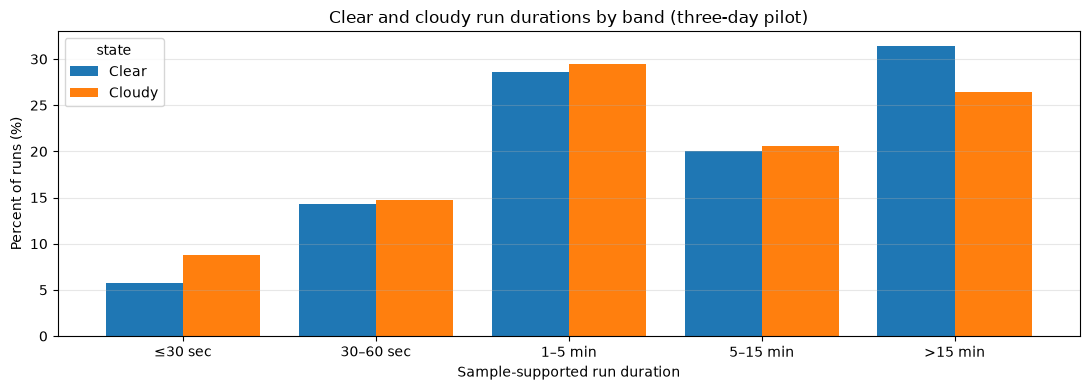

In [8]:
duration_bins = [0, 30, 60, 300, 900, np.inf]
duration_labels = ["≤30 sec", "30–60 sec", "1–5 min", "5–15 min", ">15 min"]
event_summary["duration_band"] = pd.cut( # categorize runs into duration bands
    event_summary["sample_duration_seconds"],
    bins=duration_bins,
    labels=duration_labels,
    right=True,
    include_lowest=True,
)
band_counts = pd.crosstab( #crosstab of state vs duration band
    event_summary["state_label"], event_summary["duration_band"], normalize="index"
).reindex(columns=duration_labels, fill_value=0) * 100
band_counts.index.name = "state"
print("Percentage of runs in each duration band:")
display(band_counts.round(1))
# Plot the distribution of run durations by band
ax = band_counts.T.plot(kind="bar", figsize=(11, 4), width=0.8)
ax.set_xlabel("Sample-supported run duration")
ax.set_ylabel("Percent of runs (%)")
ax.set_title("Clear and cloudy run durations by band (three-day pilot)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Visualize the full duration distribution

We can use an empirical cumulative distribution (ECDF) to show the proportion of runs shorter than each duration and compare clear and cloudy events without choosing histogram bins. 

The horizontal axis is logarithmic to show both breif and long runs. 

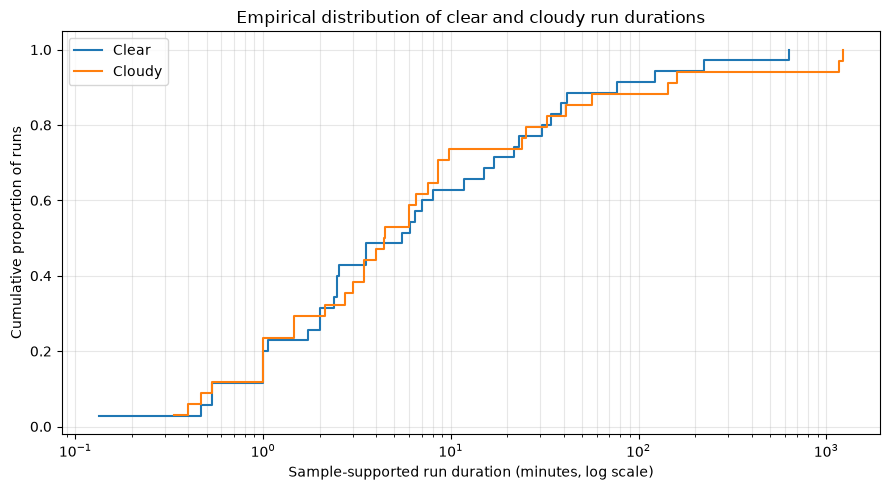

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
for label, group in event_summary.groupby("state_label"):
    values = np.sort(group["sample_duration_minutes"].to_numpy())
    ecdf = np.arange(1, len(values) + 1) / len(values)
    ax.step(values, ecdf, where="post", label=label)

ax.set_xscale("log")
ax.set_xlabel("Sample-supported run duration (minutes, log scale)")
ax.set_ylabel("Cumulative proportion of runs")
ax.set_title("Empirical distribution of clear and cloudy run durations")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Inspect an example of a short run

Does the layer count and cloud state change coherently, or does the state toggle briefly and then revert? Here, we find a short, non-boundry run (five minutes or less) and plot the coud state and layer count around it. If no such run exists, select the shortest non-boundary run available. 

Selected run:


,value
cloud_state,1
start_time,2024-01-01 20:14:20
end_time,2024-01-01 20:14:36
n_timestamps,5
state_label,Cloudy
sample_duration_seconds,20
timestamp_span_seconds,16.0
sample_duration_minutes,0.333333
left_boundary_censored,False
right_boundary_censored,False


Plot window: 2024-01-01 20:11:20 to 2024-01-01 20:17:36


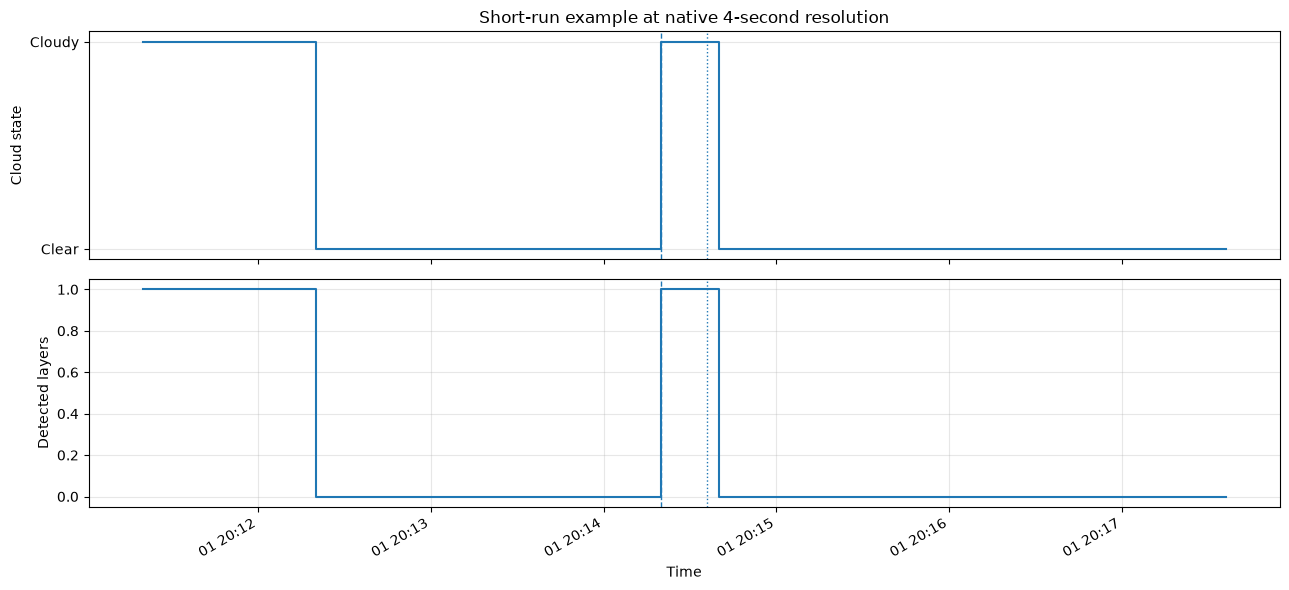

In [10]:
candidate_events = event_summary.loc[~event_summary["boundary_censored"]] # select events that are not boundary-censored
if candidate_events.empty:
    candidate_events = event_summary

short_candidates = candidate_events.loc[candidate_events["sample_duration_seconds"] <= 300]
selected_pool = short_candidates if not short_candidates.empty else candidate_events
selected_run = selected_pool.sort_values("sample_duration_seconds").iloc[0]
window_start = selected_run["start_time"] - pd.Timedelta(minutes=3)
window_end = selected_run["end_time"] + pd.Timedelta(minutes=3)
example = cloud_state_df.loc[window_start:window_end]

print("Selected run:")
display(selected_run.to_frame("value"))
print(f"Plot window: {window_start} to {window_end}")

#Plot the selected short-run example
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].step(example.index, example["cloud_state"], where="post")
axes[0].set_yticks([0, 1], labels=["Clear", "Cloudy"])
axes[0].set_ylabel("Cloud state")
axes[0].set_title("Short-run example at native 4-second resolution")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].step(example.index, example["n_cloud_layers"], where="post")
axes[1].set_ylabel("Detected layers")
axes[1].set_xlabel("Time")
axes[1].grid(True, alpha=0.3)
for ax in axes:
    ax.axvline(selected_run["start_time"], linestyle="--", linewidth=1)
    ax.axvline(selected_run["end_time"], linestyle=":", linewidth=1)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 9. Count transitions at native four-second resolution

Here, we count a state change only when the previous and current values are both known and exactly four seconds apart. This excludes transitions that cross missing time or an unknown state. 

The raw transitions rate is useful as a baseline, but it is not itself a modeling score. 

In [11]:
state = cloud_state_df["cloud_state"]
previous = state.shift()
delta = cloud_state_df.index.to_series().diff().dt.total_seconds()
known_pair = state.isin([0, 1]) & previous.isin([0, 1]) & delta.eq(4) # only consider consecutive 4-second intervals with known states

transition_counts = pd.crosstab( #crosstab of previous vs current cloud state for known 4-second intervals
    previous[known_pair].map({0: "Clear", 1: "Cloudy"}),
    state[known_pair].map({0: "Clear", 1: "Cloudy"}),
).reindex(index=["Clear", "Cloudy"], columns=["Clear", "Cloudy"], fill_value=0)
transition_counts.index.name = "Previous state"
transition_counts.columns.name = "Current state"
display(transition_counts)

n_pairs = int(known_pair.sum())
n_changes = int((state[known_pair].to_numpy() != previous[known_pair].to_numpy()).sum())
print("Adjacent known 4-second pairs:", f"{n_pairs:,}")
print("State changes:", n_changes)
print("Transition rate:", n_changes / n_pairs if n_pairs else np.nan)

Current state,Clear,Cloudy
Previous state,,
Clear,20274,34
Cloudy,34,44457


Adjacent known 4-second pairs: 64,799
State changes: 68
Transition rate: 0.0010493989104770134


## 10. Compare candidate aggregation intervals

Here, we will keep two quantities for every time bin: 

- **Cloud fraction:** cloudy observations divided by known cloudy-or-clear observations in the bin.
- **Known coverage:** fraction of timestamps in the bin with a known cloud state.

For a *diagnostic comparison only*, we also assign a majority state: cloudy if cloud fraction is greater than 0.5, clear if it is below 0.5, and unknown for an exact tie or a bin with no known observations. 

Here, we compare 20-seconds, 1 minute, and 5 minute bins. These are condidate scales for exploration, not a final choice. 


In [12]:
CANDIDATE_INTERVALS = ["20s", "1min", "5min"]
state_numeric = cloud_state_df["cloud_state"]
known_numeric = state_numeric.isin([0, 1]).astype(np.int8)  # 1 if known, 0 if unknown
cloudy_numeric = state_numeric.eq(1).astype(np.int8)  # 1 if cloudy, 0 if not

aggregated = {}
aggregation_rows = []
for interval in CANDIDATE_INTERVALS:
    known_count = known_numeric.resample(interval).sum()
    cloudy_count = cloudy_numeric.resample(interval).sum()
    n_in_bin = state_numeric.resample(interval).size()

    cloud_fraction = (cloudy_count / known_count.replace(0, np.nan)).rename("cloud_fraction")
    known_coverage = (known_count / n_in_bin).rename("known_coverage")
    aggregated_state = pd.Series(
        np.where(
            cloud_fraction > 0.5, 1,
            np.where(cloud_fraction < 0.5, 0, -1),
        ),
        index=cloud_fraction.index,
        name="aggregated_state",
        dtype=np.int8,
    )
    aggregated[interval] = pd.DataFrame({
        "cloud_fraction": cloud_fraction,
        "known_coverage": known_coverage,
        "n_timestamps": n_in_bin,
        "aggregated_state": aggregated_state,
    })

    agg_previous = aggregated_state.shift()
    valid_pair = aggregated_state.isin([0, 1]) & agg_previous.isin([0, 1])
    n_transition_pairs = int(valid_pair.sum())
    n_transition_changes = int(
        (aggregated_state[valid_pair].to_numpy() != agg_previous[valid_pair].to_numpy()).sum()
    )

    aggregation_rows.append({
        "interval": interval,
        "n_bins": len(aggregated_state),
        "median_cloud_fraction": float(cloud_fraction.median()),
        "p10_cloud_fraction": float(cloud_fraction.quantile(0.10)),
        "p90_cloud_fraction": float(cloud_fraction.quantile(0.90)),
        "mean_known_coverage": float(known_coverage.mean()),
        "tie_or_no_data_bins": int((aggregated_state == -1).sum()),
        "adjacent_known_bin_pairs": n_transition_pairs,
        "state_changes_between_bins": n_transition_changes,
        "transition_rate_between_bins": (
            n_transition_changes / n_transition_pairs if n_transition_pairs else np.nan
        ),
    })

aggregation_summary = pd.DataFrame(aggregation_rows).set_index("interval")
display(aggregation_summary)

,n_bins,median_cloud_fraction,p10_cloud_fraction,p90_cloud_fraction,mean_known_coverage,tie_or_no_data_bins,adjacent_known_bin_pairs,state_changes_between_bins,transition_rate_between_bins
interval,,,,,,,,,
20s,12960,1.0,0.0,1.0,1.0,0,12959,67,0.005170
1min,4320,1.0,0.0,1.0,1.0,0,4319,59,0.013661
5min,864,1.0,0.0,1.0,1.0,0,863,27,0.031286


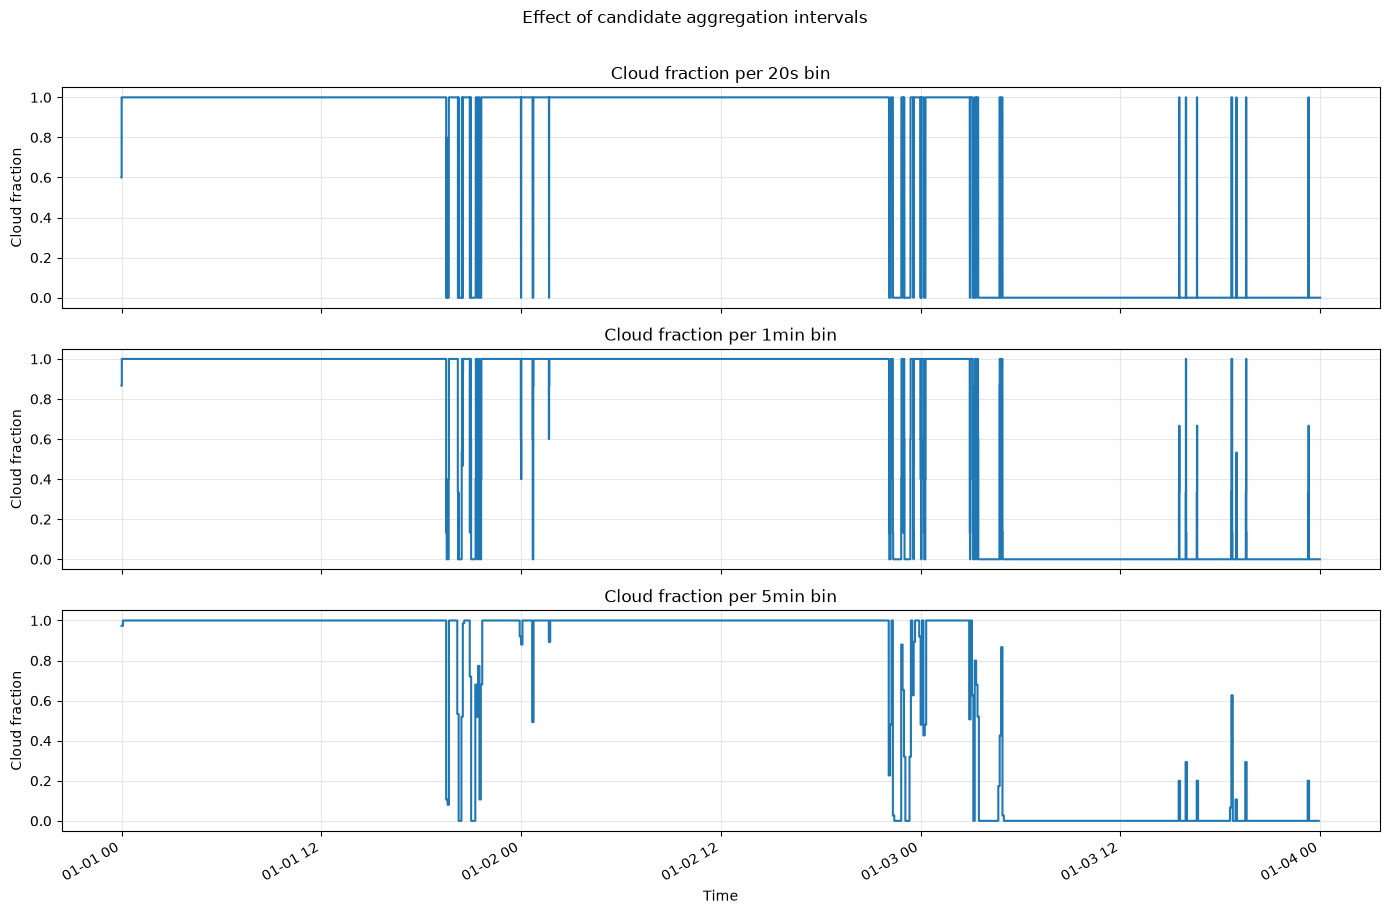

In [13]:
fig, axes = plt.subplots(len(CANDIDATE_INTERVALS), 1, figsize=(14, 9), sharex=True)
for ax, interval in zip(axes, CANDIDATE_INTERVALS):
    frame = aggregated[interval]
    ax.step(frame.index, frame["cloud_fraction"], where="post")
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel("Cloud fraction")
    ax.set_title(f"Cloud fraction per {interval} bin")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time")
fig.suptitle("Effect of candidate aggregation intervals", y=1.01)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 11. Interpretations

Its evident that clear and cloudy run durations are strongly right-skewed. Although the median observed run lasts approximately four to five minutes, a substantial proportion of runs persist for much longer, with occasional events extending over many hours. Approximately 499% of clear runs and 53% of cloudy runs last five minutes or less, while roughly 69% and 74%, respectively, last fifteen minutes or less. Two clear runs touch the observation-window boundaries, so their true durations may not be fully observed. 

At the native four-second resoltution, only 68 of 64,799 adjacent known-state pairs change state. This indicates strong short-term persistence and suggests that a next-sample prediction target could be uninformative, despite producing high apparent accuracy. Temporal aggregation also affects the representation of cloud transitions: twenty-second aggregation preserves nearly all observed changes in this sample, while five-minute aggregation reduces the number of detected changes substantially. 

These results provide an initial basis for selecting a useful modeling timescale, but the three-day sample is too limited to establish representative duration distributions or finalize the prediction horizon. The aggregation comparison also uses a majority-state rule, which can suppress short-lived events. 

## 12. Conclusions and Next Steps

The cloud-state and temporal-dynamics functions are ready for broader validation. The next step is to apply the same analysis to a substantially longer period, preferably while applying QC in memory rahter than producing a separate QC file for every day. This will show whether the short-run frequencies, long-duration tails, and aggregation effects observed here persist across different atmospheric conditions. 

The aggregation analysis should also report the proportion of fully clear, fully cloudy, and mized-state bins, alongside cloud fraction and transition counts.

After the broader analysis, the project can select a temporal resolution and define the persistence/dissipation target. 